# How Does the Federal Reserve Set Interest Rates? Evidence from 1960–2026

**Questions**
1. How have the federal funds rate, inflation and unemployment moved together over the last six decades?
2. Does a simple rule, the Taylor rule, describe what the Fed actually did? When did the Fed deviate from it most?
3. Has the Fed's reaction to inflation changed across eras? In particular, has it followed the *Taylor principle* of raising rates by more than one-for-one with inflation?
4. How did the 2022–23 tightening cycle compare with past hiking cycles?

**Data (monthly, July 1954 to October 2026):**
- Effective federal funds rate: Federal Reserve Board, [H.15 Selected Interest Rates](https://www.federalreserve.gov/releases/h15/) (daily values averaged to monthly)
- Consumer Price Index for All Urban Consumers (CPI-U), seasonally adjusted: U.S. Bureau of Labor Statistics, series `CUSR0000SA0`
- Unemployment rate, seasonally adjusted: U.S. Bureau of Labor Statistics, series `LNS14000000`

**Tools:** Python, pandas, matplotlib, statsmodels (OLS with Newey-West standard errors).

## 1. Setup and data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from pathlib import Path

DEEP, DARK, MID, LIGHT, SOFT, PLUM, BLUSH = "#880E4F", "#D81B60", "#F48FB1", "#F8BBD0", "#E8A0BF", "#AD1457", "#FCE4EC"   # pink palette
plt.rcParams.update({"figure.figsize": (11, 4.8), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold", "svg.fonttype": "none"})
Path("images").mkdir(exist_ok=True)

raw = pd.read_csv("data/us_macro_monthly.csv", parse_dates=["date"], index_col="date")
df = raw.copy()
df["inflation"] = (df.cpi / df.cpi.shift(12) - 1) * 100          # CPI inflation, % change from a year earlier
df = df.loc["1960-01-01":].copy()
print(df.shape, df.index.min().date(), "to", df.index.max().date())
print("missing values:", int(df.isna().sum().sum()))
df[["fed_funds", "inflation", "unemployment"]].describe().round(2)

(801, 4) 1960-01-01 to 2026-10-01
missing values: 0


,fed_funds,inflation,unemployment
count,801.00,801.00,801.00
mean,4.78,3.74,5.84
std,3.60,2.77,1.70
min,0.05,-1.96,3.40
25%,2.00,1.89,4.60
50%,4.65,3.01,5.60
75%,6.47,4.62,6.90
max,19.10,14.59,14.80


## 2. Sixty-six years of rates, inflation and unemployment

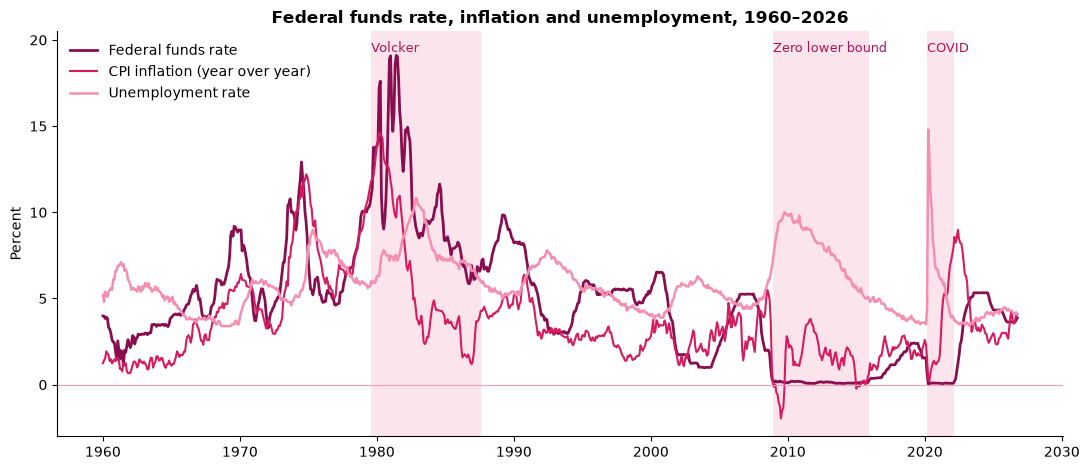

,peak fed funds,peak inflation,peak unemployment
date,1981-06,1980-03,2020-04
value,19.1,14.592275,14.8


In [2]:
eras = [("1979-08", "1987-08", "Volcker"), ("2008-12", "2015-12", "Zero lower bound"), ("2020-03", "2022-03", "COVID")]
fig, ax = plt.subplots()
for start, end, name in eras:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=BLUSH, lw=0)
    ax.text(pd.Timestamp(start), 19.3, name, fontsize=9, color=PLUM)
ax.plot(df.index, df.fed_funds, color=DEEP, lw=2, label="Federal funds rate")
ax.plot(df.index, df.inflation, color=DARK, lw=1.5, label="CPI inflation (year over year)")
ax.plot(df.index, df.unemployment, color=MID, lw=1.8, label="Unemployment rate")
ax.axhline(0, color=SOFT, lw=0.8)
ax.set_ylabel("Percent")
ax.set_ylim(-3, 20.5)
ax.set_title("Federal funds rate, inflation and unemployment, 1960–2026")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig("images/rates_inflation_unemployment.svg")
plt.show()

peaks = pd.DataFrame({
    "peak fed funds": [df.fed_funds.idxmax().strftime("%Y-%m"), df.fed_funds.max()],
    "peak inflation": [df.inflation.idxmax().strftime("%Y-%m"), df.inflation.max()],
    "peak unemployment": [df.unemployment.idxmax().strftime("%Y-%m"), df.unemployment.max()],
}, index=["date", "value"])
peaks

In [3]:
dec = df.groupby((df.index.year // 10) * 10)[["fed_funds", "inflation", "unemployment"]].mean()
dec["real_rate"] = dec.fed_funds - dec.inflation
dec.index = [f"{d}s" for d in dec.index]
dec.round(2)

,fed_funds,inflation,unemployment,real_rate
1960s,4.18,2.33,4.78,1.85
1970s,7.10,7.09,6.22,0.01
1980s,9.97,5.56,7.27,4.41
1990s,5.14,3.01,5.76,2.14
2000s,2.95,2.57,5.54,0.38
2010s,0.61,1.77,6.22,-1.16
2020s,2.85,3.93,4.77,-1.09


The chart covers three very different periods for U.S. monetary policy:

- **The Great Inflation (late 1960s to 1980).** Inflation rose in waves and peaked at **14.6% in March 1980**. Through the 1970s the funds rate moved roughly *with* inflation instead of ahead of it, so the average **real** rate (fed funds minus inflation) was about **0.0%**. Monetary policy was not restraining inflation.
- **The Volcker shock (1979–1987).** Paul Volcker pushed the funds rate to a record **19.1% in June 1981**. The average real rate in the 1980s jumped to **+4.4%**, the highest of any decade. Inflation came down, at the cost of two recessions and unemployment near 11%.
- **Low rates and the zero lower bound (2008–2021).** After the 2008 financial crisis, and again during COVID, the Fed held rates near zero. Real rates were **negative on average in both the 2010s (−1.2%) and the 2020s so far (−1.1%)**. Unemployment hit its highest point in the sample, **14.8% in April 2020**.

The 2021–22 inflation surge shows up clearly as the dark pink spike near the right edge. It was followed by one of the fastest rises in the funds rate on record.

## 3. The Taylor rule

John Taylor (1993) proposed a simple rule for the policy rate:

$$ i_t = r^* + \pi_t + 0.5\,(\pi_t - \pi^*) + 0.5\,\text{output gap}_t $$

with a neutral real rate $r^* = 2\%$ and an inflation target $\pi^* = 2\%$. Monthly GDP is not available, so I replace the output gap with the unemployment gap using Okun's law (output gap ≈ −2 × (unemployment − natural rate)). That gives

$$ i_t = 2 + \pi_t + 0.5\,(\pi_t - 2) + 1.0\,(u^* - u_t) $$

I assume a constant natural rate of unemployment $u^* = 5\%$. That is a simplification: estimates of the natural rate were closer to 6% in the 1970s and 80s and closer to 4% to 4.5% recently.

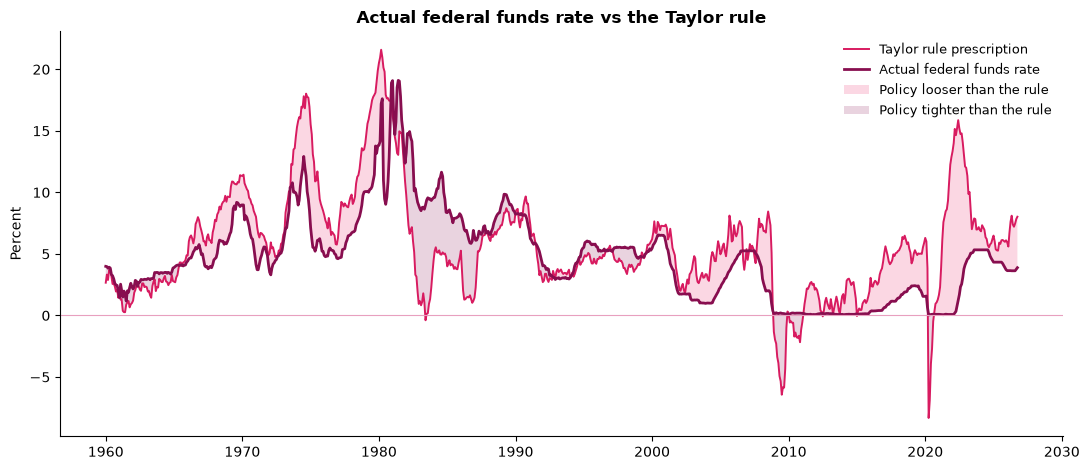

In [4]:
U_STAR, PI_STAR, R_STAR = 5.0, 2.0, 2.0
df["taylor"] = R_STAR + df.inflation + 0.5 * (df.inflation - PI_STAR) + 1.0 * (U_STAR - df.unemployment)
df["gap"] = df.fed_funds - df.taylor     # positive = policy tighter than the rule, negative = looser

fig, ax = plt.subplots()
ax.plot(df.index, df.taylor, color=DARK, lw=1.4, label="Taylor rule prescription")
ax.plot(df.index, df.fed_funds, color=DEEP, lw=2, label="Actual federal funds rate")
ax.fill_between(df.index, df.fed_funds, df.taylor, where=df.fed_funds < df.taylor, color=MID, alpha=0.35, lw=0,
                label="Policy looser than the rule")
ax.fill_between(df.index, df.fed_funds, df.taylor, where=df.fed_funds >= df.taylor, color=DEEP, alpha=0.18, lw=0,
                label="Policy tighter than the rule")
ax.axhline(0, color=SOFT, lw=0.8)
ax.set_ylabel("Percent")
ax.set_title("Actual federal funds rate vs the Taylor rule")
ax.legend(frameon=False, loc="upper right", fontsize=9)
plt.tight_layout()
plt.savefig("images/taylor_rule_vs_actual.svg")
plt.show()

In [5]:
periods = {"1960–1979": ("1960", "1979-07"), "Volcker 1979–1987": ("1979-08", "1987-07"),
           "Greenspan 1987–2006": ("1987-08", "2006-01"), "Bernanke 2006–2014": ("2006-02", "2014-01"),
           "Yellen 2014–2018": ("2014-02", "2018-01"), "Powell 2018–2026": ("2018-02", "2026-10")}
gap_tab = pd.DataFrame({name: {"avg actual rate": df.loc[a:b, "fed_funds"].mean(),
                               "avg Taylor rate": df.loc[a:b, "taylor"].mean(),
                               "avg gap (actual - rule)": df.loc[a:b, "gap"].mean(),
                               "avg absolute gap": df.loc[a:b, "gap"].abs().mean(),
                               "corr(actual, rule)": df.loc[a:b, ["fed_funds", "taylor"]].corr().iloc[0, 1]}
                        for name, (a, b) in periods.items()}).T
print(gap_tab.round(2).to_string())
print()
largest = df.gap.resample("YS").mean()
print("Most loose years vs the rule:\n", largest.nsmallest(5).round(2).to_string())
print("\nMost tight years vs the rule:\n", largest.nlargest(5).round(2).to_string())

                     avg actual rate  avg Taylor rate  avg gap (actual - rule)  avg absolute gap  corr(actual, rule)
1960–1979                       5.49             7.34                    -1.84              2.27                0.93
Volcker 1979–1987              10.65             7.63                     3.03              5.11                0.71
Greenspan 1987–2006             4.81             5.11                    -0.30              1.19                0.76
Bernanke 2006–2014              1.53             2.02                    -0.49              1.96                0.74
Yellen 2014–2018                0.43             2.83                    -2.40              2.41                0.82
Powell 2018–2026                2.67             6.75                    -4.09              4.52                0.16

Most loose years vs the rule:
 date
2022-01-01   -12.67
2021-01-01    -7.58
1974-01-01    -6.34
1979-01-01    -5.79
1980-01-01    -5.76

Most tight years vs the rule:
 date
1983-01

The Taylor rule tracks the broad shape of policy, but the gaps are revealing:

| Period | Avg actual | Avg rule | Avg gap | Avg absolute gap |
|---|---:|---:|---:|---:|
| 1960–1979 | 5.49 | 7.34 | −1.84 | 2.27 |
| Volcker 1979–1987 | 10.65 | 7.63 | **+3.03** | 5.11 |
| Greenspan 1987–2006 | 4.81 | 5.11 | −0.30 | **1.19** |
| Bernanke 2006–2014 | 1.53 | 2.02 | −0.49 | 1.96 |
| Yellen 2014–2018 | 0.43 | 2.83 | −2.40 | 2.41 |
| Powell 2018–2026 | 2.67 | 6.75 | **−4.09** | 4.52 |

- **The Greenspan era followed the rule most closely**, with an average miss of only about 1.2 points. That matches Taylor's own claim that his rule described Fed policy well in that period.
- **Before 1979 the Fed was consistently looser than the rule** (by about 1.8 points on average). Under **Volcker it was much tighter** (+3.0 points); the tightest years in the sample are 1982 to 1986, as the Fed held real rates high to lock in lower inflation.
- **The biggest deviations are recent.** The loosest years against the rule are **2022 (−12.7 points) and 2021 (−7.6)**, ahead of 1974, 1979 and 1980. With inflation at 7% to 9%, the rule called for a funds rate of about 15%, while the Fed kept rates near zero until March 2022. Under Powell the correlation between actual policy and the rule is only 0.16.
- The rule also has blind spots. In 2009 and 2020 it called for **negative** rates (as low as about −6% and −8%), which the Fed could not set, so it used tools such as asset purchases (quantitative easing) and forward guidance instead.

## 4. Has the Fed's reaction to inflation changed?

Instead of assuming Taylor's coefficients, I **estimate** a policy rule for each era:

$$ i_t = \alpha + \beta_\pi\,\pi_t + \beta_u\,(u_t - u^*) + \varepsilon_t $$

The **Taylor principle** says $\beta_\pi$ should be greater than 1: when inflation rises by 1 point, the Fed should raise the nominal rate by more than 1 point so the *real* rate goes up and cools the economy. Monthly macro data is strongly autocorrelated, so I use Newey-West (HAC) standard errors with 12 lags.

The 2009–2015 and 2020–2021 zero-lower-bound months are excluded from the modern era, because the Fed could not cut below zero and used other tools then.

In [6]:
df["u_gap"] = df.unemployment - U_STAR
zlb = (df.fed_funds < 0.25)
samples = {"1960–1979 (pre-Volcker)": df.loc["1960":"1979-07"],
           "1987–2007 (Greenspan era)": df.loc["1987-08":"2007-12"],
           "2008–2026 (excl. zero bound)": df.loc["2008":"2026-10"][~zlb.loc["2008":"2026-10"]]}
rows = []
for name, d in samples.items():
    m = smf.ols("fed_funds ~ inflation + u_gap", data=d).fit(cov_type="HAC", cov_kwds={"maxlags": 12})
    lo, hi = m.conf_int().loc["inflation"]
    rows.append({"period": name, "months": int(m.nobs), "beta_inflation": m.params["inflation"],
                 "95% CI low": lo, "95% CI high": hi, "beta_unemployment_gap": m.params["u_gap"],
                 "p (unemployment)": m.pvalues["u_gap"], "R²": m.rsquared,
                 "Taylor principle (beta > 1)?": "Yes" if lo > 1 else ("No" if hi < 1 else "Unclear")})
rules = pd.DataFrame(rows).set_index("period")
rules.round(3)

,months,beta_inflation,95% CI low,95% CI high,beta_unemployment_gap,p (unemployment),R²,Taylor principle (beta > 1)?
period,,,,,,,,
1960–1979 (pre-Volcker),235,0.782,0.710,0.855,-0.784,0.000,0.884,No
1987–2007 (Greenspan era),245,1.354,0.871,1.837,-0.877,0.000,0.532,Unclear
2008–2026 (excl. zero bound),116,0.149,-0.266,0.564,-0.893,0.021,0.167,No


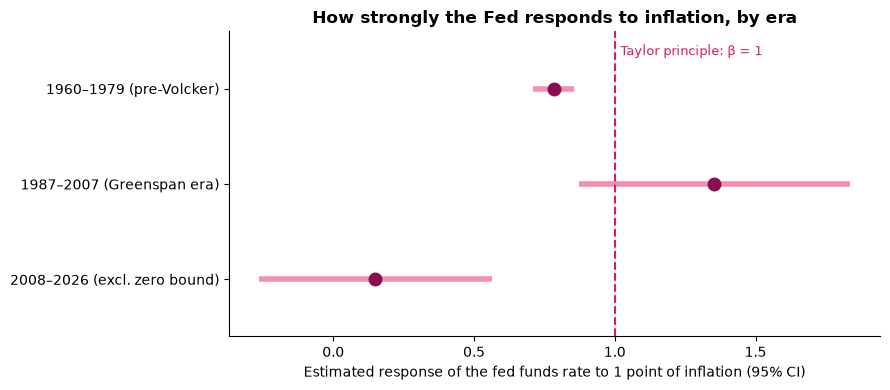

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(rules))[::-1]
ax.errorbar(rules.beta_inflation, y, xerr=[rules.beta_inflation - rules["95% CI low"], rules["95% CI high"] - rules.beta_inflation],
            fmt="o", color=DEEP, ecolor=MID, elinewidth=4, capsize=0, ms=9)
ax.axvline(1, color=DARK, ls="--", lw=1.5)
ax.text(1.02, y.max() + 0.35, "Taylor principle: β = 1", color=DARK, fontsize=9)
ax.set_yticks(y, rules.index)
ax.set_ylim(-0.6, y.max() + 0.6)
ax.set_xlabel("Estimated response of the fed funds rate to 1 point of inflation (95% CI)")
ax.set_title("How strongly the Fed responds to inflation, by era")
plt.tight_layout()
plt.savefig("images/inflation_response_by_era.svg")
plt.show()

| Period | Months | Inflation response β | 95% CI | Unemployment-gap response | R² |
|---|---:|---:|---|---:|---:|
| 1960–1979 | 235 | **0.78** | 0.71 – 0.86 | −0.78 | 0.88 |
| 1987–2007 | 245 | **1.35** | 0.87 – 1.84 | −0.88 | 0.53 |
| 2008–2026 (excl. zero bound) | 116 | **0.15** | −0.27 – 0.56 | −0.89 | 0.17 |

- **Before Volcker, the Fed violated the Taylor principle.** Each 1-point rise in inflation was met with only about a 0.78-point rise in the funds rate, and the whole confidence interval is below 1. Real rates *fell* as inflation rose, which helps explain why inflation kept climbing in the 1970s. This matches a well-known finding by Clarida, Galí and Gertler (2000).
- **In the Greenspan era the estimated response is 1.35**, above 1, consistent with the Taylor principle. The confidence interval is wide (0.87 to 1.84), so the evidence is suggestive rather than conclusive.
- **After 2008, a simple same-month rule no longer fits** (R² = 0.17, and the inflation coefficient is not significantly different from zero). This is not proof that the Fed stopped caring about inflation. Instead, the relationship is dominated by timing: the Fed held rates at zero while inflation surged in 2021, then raised rates sharply in 2022–23 as inflation was already falling. A rule that allows for lags, or that uses inflation *forecasts*, would fit this period better.
- The **response to unemployment is remarkably stable**: in every era, each point of unemployment above 5% is associated with a funds rate about 0.8 to 0.9 points lower, and it is significant in all three periods.

## 5. The 2022–23 hiking cycle in historical context

In [8]:
# a hiking cycle runs from liftoff after a local low in the funds rate to the following local high, with at least a 1.5-point rise
ff = df.fed_funds
lows, highs = [], []
win = 12
for i in range(win, len(ff) - win):
    seg = ff.iloc[i - win:i + win + 1]
    if ff.iloc[i] == seg.min():
        lows.append(ff.index[i])
    if ff.iloc[i] == seg.max():
        highs.append(ff.index[i])
cycles = []
for lo in lows:
    nxt = [h for h in highs if h > lo]
    if not nxt:
        continue
    hi = nxt[0]
    # the cycle starts at liftoff: the last month the rate was still within 0.25 points of the low
    flat = ff.loc[lo:hi]
    lo = flat[flat <= ff[lo] + 0.25].index[-1]
    rise = ff[hi] - ff[lo]
    if rise >= 1.5 and not any(c["start"] == lo or c["end"] == hi for c in cycles):
        months = (hi.year - lo.year) * 12 + hi.month - lo.month
        cycles.append({"start": lo, "end": hi, "from %": ff[lo], "to %": ff[hi], "rise (pts)": rise,
                       "months": months, "pts per year": rise / months * 12,
                       "inflation at start %": df.inflation[lo], "inflation at peak rate %": df.inflation[hi]})
cyc = pd.DataFrame(cycles).drop_duplicates(subset="end", keep="first")
cyc["start"], cyc["end"] = cyc.start.dt.strftime("%Y-%m"), cyc.end.dt.strftime("%Y-%m")
cyc.round(2).reset_index(drop=True)

,start,end,from %,to %,rise (pts),months,pts per year,inflation at start %,inflation at peak rate %
0,1961-07,1963-10,1.17,3.50,2.33,27,1.04,1.25,1.22
1,1964-11,1966-11,3.52,5.76,2.24,24,1.12,1.40,3.56
2,1967-10,1969-08,3.88,9.19,5.31,22,2.90,2.59,5.43
3,1972-02,1974-07,3.30,12.92,9.62,29,3.98,3.76,11.54
4,1977-04,1981-06,4.73,19.10,14.37,50,3.45,6.95,9.70
5,1983-05,1984-08,8.63,11.64,3.01,15,2.41,3.44,4.30
6,1987-02,1989-03,6.10,9.85,3.75,25,1.80,1.91,4.89
7,1994-01,1995-04,3.05,6.05,3.00,15,2.40,2.45,3.13
8,1999-06,2000-07,4.76,6.54,1.78,13,1.64,1.97,3.60
9,2004-06,2007-02,1.03,5.26,4.23,32,1.59,3.17,2.42


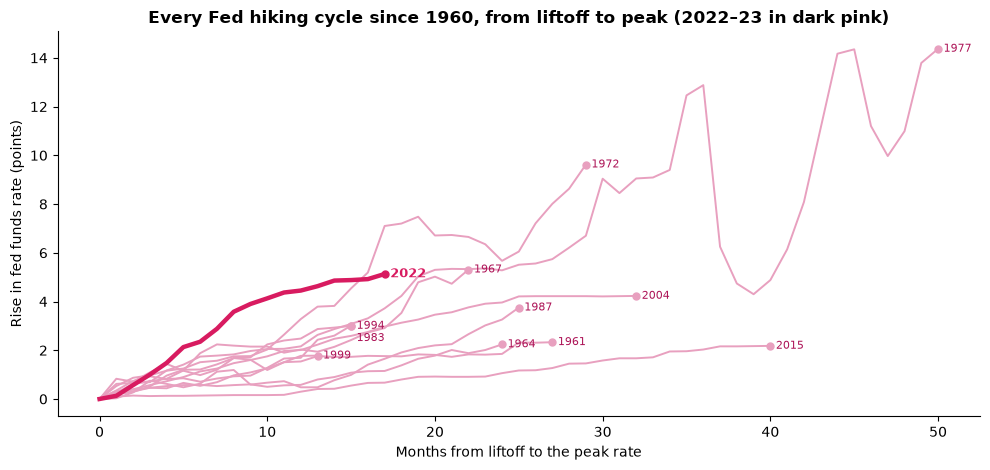

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for _, c in cyc.iterrows():
    path = ff.loc[pd.Timestamp(c.start):pd.Timestamp(c.end)]
    x = np.arange(len(path))
    y = path.values - path.values[0]
    recent = c.start.startswith("2022")
    ax.plot(x, y, lw=3.2 if recent else 1.4, color=DARK if recent else SOFT, zorder=3 if recent else 2)
    ax.plot(x[-1], y[-1], "o", ms=5, color=DARK if recent else SOFT)
    ax.annotate(c.start[:4], (x[-1], y[-1]), xytext=(4, -9 if c.start.startswith("1983") else 0), textcoords="offset points", va="center",
                fontsize=9 if recent else 8, fontweight="bold" if recent else "normal", color=DARK if recent else PLUM)
ax.set_xlabel("Months from liftoff to the peak rate")
ax.set_ylabel("Rise in fed funds rate (points)")
ax.set_title("Every Fed hiking cycle since 1960, from liftoff to peak (2022–23 in dark pink)")
plt.tight_layout()
plt.savefig("images/hiking_cycles.svg")
plt.show()

I found **12 hiking cycles** since 1960 with a rise of at least 1.5 points. The 2022–23 cycle stands out in three ways:

- **Speed:** the funds rate rose from 0.20% to 5.33%, **+5.13 points in 17 months**, or about **3.6 points per year**. Only the 1972–74 cycle (4.0 points per year) was faster, so it outpaced even the Volcker-era hikes of 1977–81 (3.45 points per year). The median cycle rose about 2.1 points per year.
- **Late start:** CPI inflation was already **8.6%** at liftoff in March 2022, the highest starting inflation of any cycle. In most cycles inflation was between 1% and 4% when hikes began, and even the 1977 cycle started at 7.0%. This is the "behind the curve" criticism of the Fed in 2021, seen in the data.
- **Outcome:** by the peak rate in August 2023, inflation had fallen to **3.7%**. Unemployment stayed between 3.4% and 3.7% for the entire cycle, unlike the Volcker disinflation.

By contrast, the 2015–2019 cycle was the slowest on record: +2.2 points over 40 months, or about 0.65 points per year.

## 6. Conclusions


1. **Real interest rates explain the inflation story.** The 1970s had an average real rate of about 0%, and inflation rose. The 1980s averaged +4.4%, and inflation fell.
2. **The Taylor rule describes the Greenspan years well** (average miss of about 1.2 points) but not the 1970s, the Volcker years or 2021–22, when policy was about 7 to 13 points looser than the rule.
3. **The Fed's inflation response has changed over time.** It was below 1 before 1979, which broke the Taylor principle, and about 1.35 in 1987–2007. After 2008, a simple same-month rule stops fitting, mostly because of the zero lower bound and the delayed response in 2021.
4. **The 2022–23 cycle was the fastest tightening since the early 1970s**, but it started with the highest inflation of any cycle on record.

**Limitations:** the Taylor rule here uses a constant natural unemployment rate of 5% and CPI instead of the Fed's preferred PCE inflation measure; the estimated rules ignore lags, interest-rate smoothing and inflation expectations; and the Fed also used tools other than the funds rate (asset purchases, forward guidance) during the zero-lower-bound years. Next steps would be a forward-looking rule with lagged rates, real-time data and time-varying estimates of the natural rate.